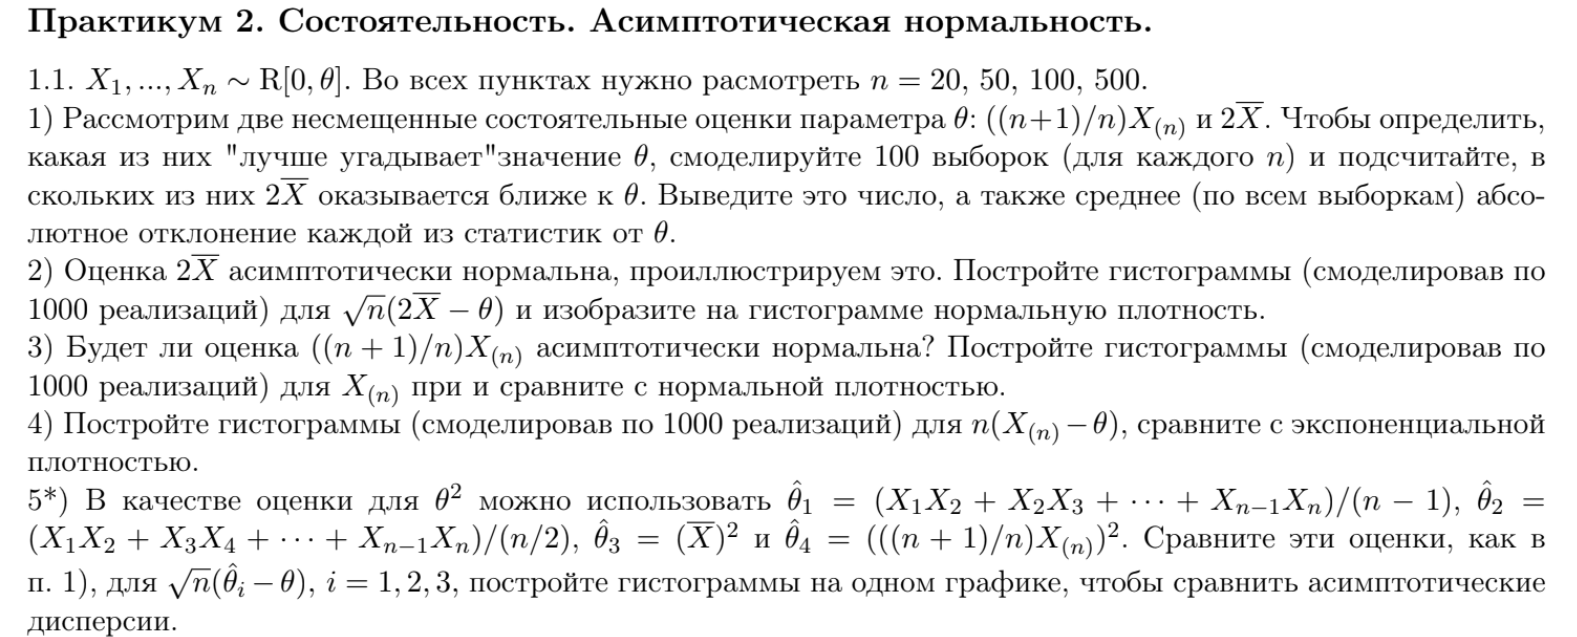

# **1**

In [136]:
import random
import numpy as np
import statistics
import pandas as pd
import math
import seaborn as sb
from scipy.stats import norm, expon

theta = 5
print("theta = "+ str(theta))

theta = 5


In [137]:
N=[20,50,100,500]
df=pd.DataFrame(data={"Размер":[],"o2<o1 раз":[],"delta о1":[],"delta о2":[]})

for n in N:
  sum = 0
  delta1=0
  delta2=0
  for i in range(0, 100):
    uniform_data = np.random.uniform(0, theta, n)
    o1=(n+1)/n* uniform_data.max()
    o2=statistics.fmean(uniform_data)*2
    if (abs(o2 - theta) < abs(o1- theta)):
      sum=sum+1
    delta1=delta1+abs(o1- theta)
    delta2=delta2+abs(o2- theta)
  df.loc[len(df)] = {'Размер': n, 'o2<o1 раз': sum, 'delta о1':delta1/n,'delta о2':delta2/n }
display(df)

,Размер,o2<o1 раз,delta о1,delta о2
0,20,17,0.894337,2.751536
1,50,12,0.150130,0.623935
2,100,8,0.034796,0.240578
3,500,3,0.001237,0.021203


первая оценка приближает лучше

# **2**

In [138]:

uniform_df_1000 = pd.DataFrame(data = {"Оценка20": [],'Оценка50':[],'Оценка100':[],'Оценка500':[]})

for i in range(0, 1000):
    uniform_data20 = np.random.uniform(0, theta, 20)
    uniform_data50 = np.random.uniform(0, theta, 50)
    uniform_data100 = np.random.uniform(0, theta, 100)
    uniform_data500 = np.random.uniform(0, theta, 500)
    uniform_df_1000.loc[len(uniform_df_1000)] = {'Оценка20': math.sqrt(20)*(2*statistics.fmean(uniform_data20)-theta),
                                                 'Оценка50': math.sqrt(50)*(2*statistics.fmean(uniform_data50)-theta),
                                                 'Оценка100': math.sqrt(100)*(2*statistics.fmean(uniform_data100)-theta),
                                                 'Оценка500': math.sqrt(500)*(2*statistics.fmean(uniform_data500)-theta)
                                                 }
display(uniform_df_1000)

,Оценка20,Оценка50,Оценка100,Оценка500
0,4.424465,-1.012138,-2.263284,-6.520144
1,0.654899,-1.742175,2.395736,2.154579
2,-1.830463,-0.650228,3.713470,0.333050
3,2.177971,-2.905007,0.627089,-2.913331
4,2.101073,-2.987587,-5.535903,-1.192112
...,...,...,...,...
995,-0.143180,1.921732,0.211630,-2.426553
996,2.937133,-0.679091,-3.562362,5.174604
997,1.598086,-0.811788,-1.225968,2.200425
998,-1.290267,5.210444,-0.371056,-0.769847


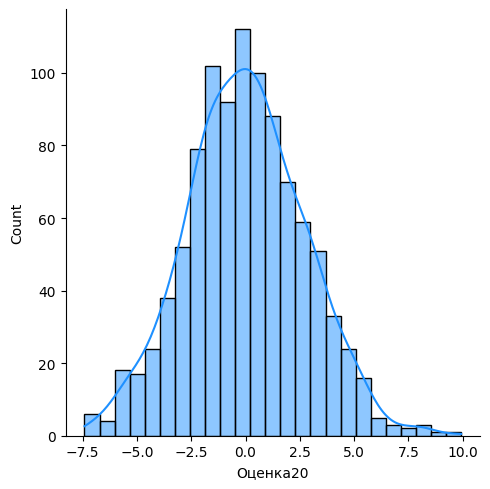

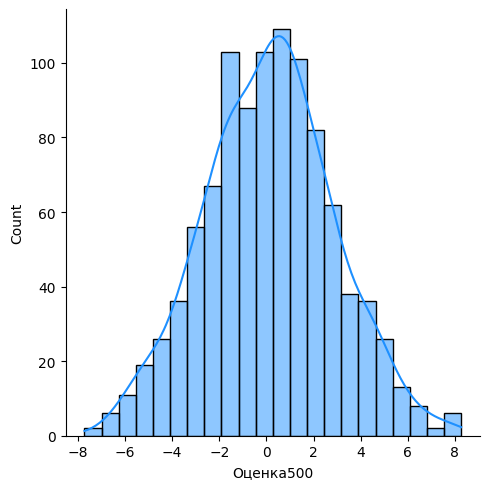

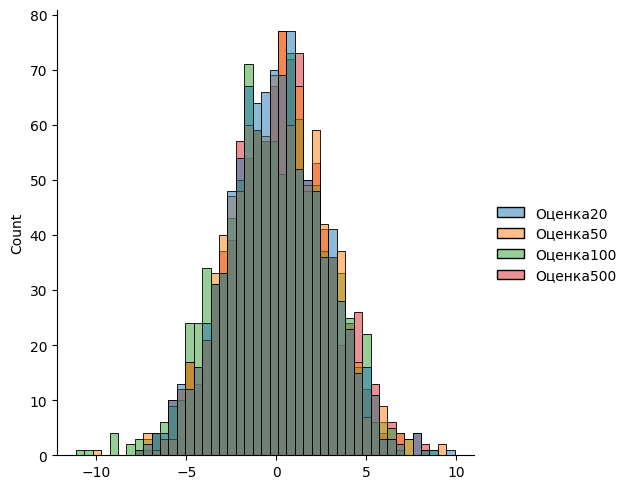

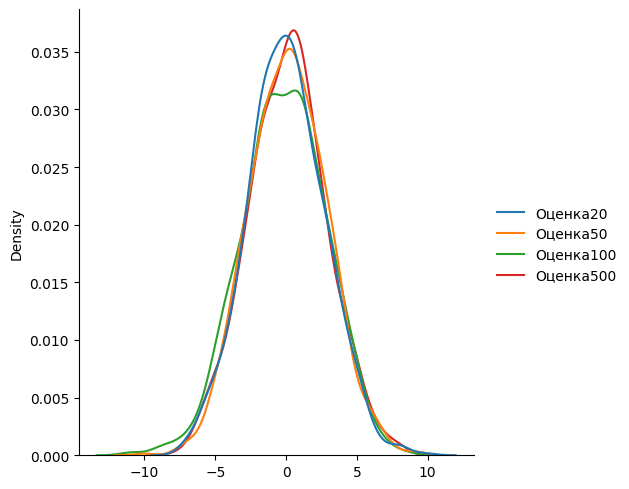

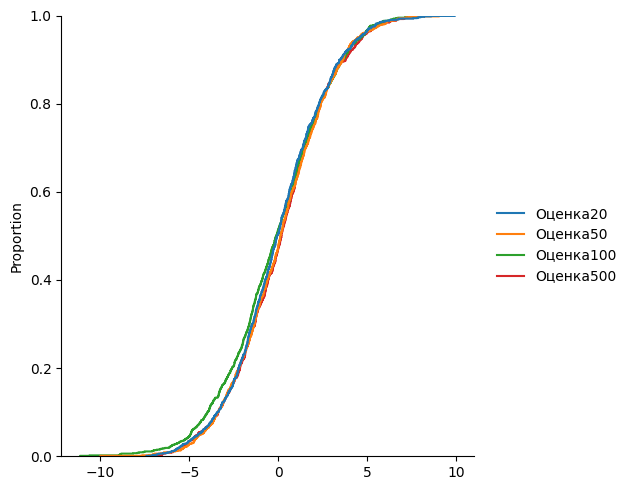

In [139]:
sb.displot(uniform_df_1000["Оценка20"], color="dodgerblue", kde = True)
sb.displot(uniform_df_1000["Оценка500"], color="dodgerblue", kde = True)
sb.displot(uniform_df_1000)
sb.displot(uniform_df_1000, kind="kde")
sb.displot(uniform_df_1000, kind="ecdf")

# **3**

In [140]:
uniform_df_1000 = pd.DataFrame(data = {"Оценка20": [],'Оценка50':[],'Оценка100':[],'Оценка500':[]})

for i in range(0, 1000):
    uniform_data20 = np.random.uniform(0, theta, 20)
    uniform_data50 = np.random.uniform(0, theta, 50)
    uniform_data100 = np.random.uniform(0, theta, 100)
    uniform_data500 = np.random.uniform(0, theta, 500)
    uniform_df_1000.loc[len(uniform_df_1000)] = {'Оценка20': (20+1)/20*uniform_data20.max(),
                                                 'Оценка50': (50+1)/50*uniform_data50.max(),
                                                 'Оценка100': (100+1)/100*uniform_data100.max(),
                                                 'Оценка500': (500+1)/500*uniform_data500.max()
                                                 }
display(uniform_df_1000)

,Оценка20,Оценка50,Оценка100,Оценка500
0,4.801866,4.920786,5.033918,5.005465
1,5.072147,5.088746,5.047619,4.995907
2,5.192832,5.096189,5.039097,4.991587
3,5.023339,4.987536,5.006727,5.009780
4,5.214513,5.083579,5.031718,5.003278
...,...,...,...,...
995,5.240963,5.057310,5.048920,5.009116
996,4.847706,4.910027,5.013120,5.009952
997,5.201204,5.034358,5.009245,5.004199
998,4.516495,4.907032,4.882427,5.009502


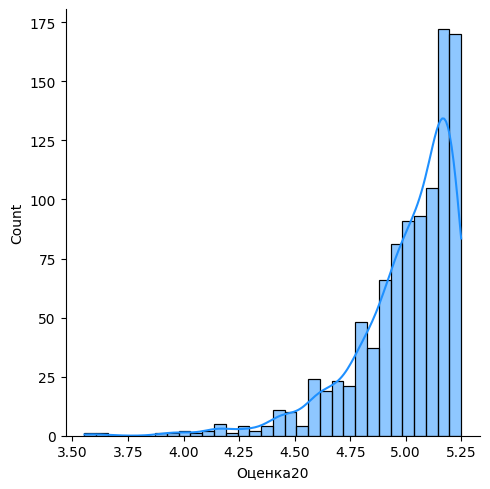

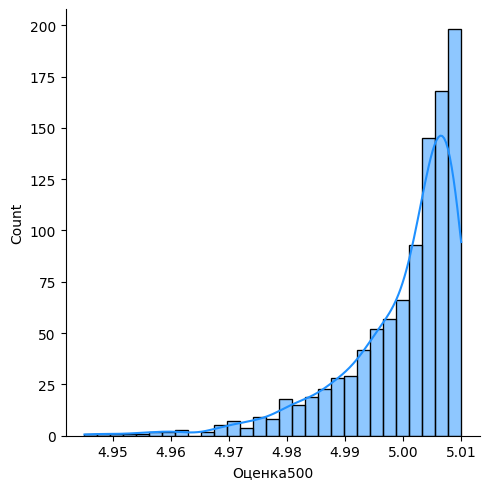

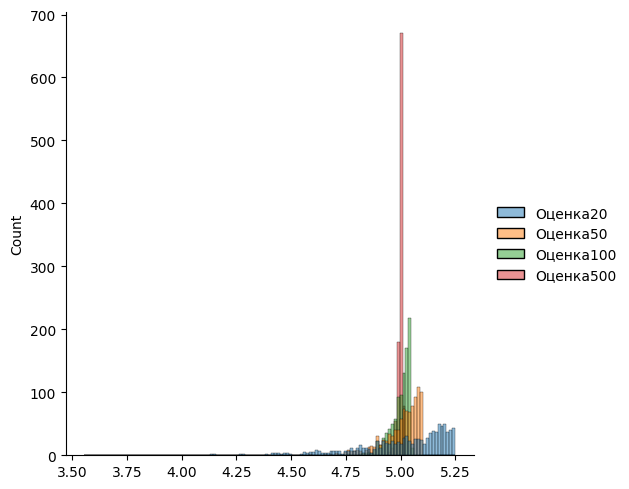

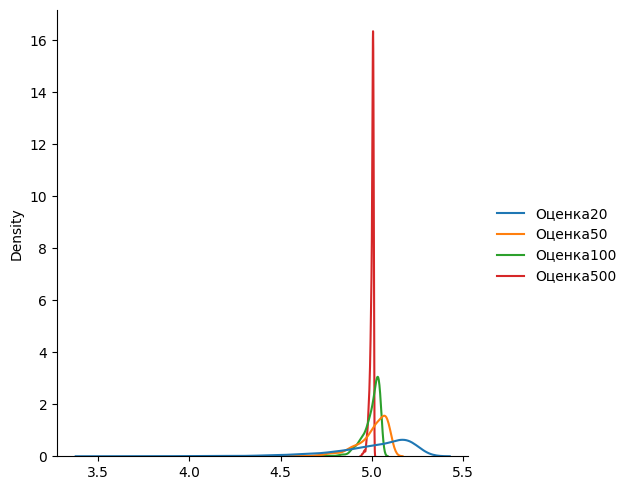

In [141]:
sb.displot(uniform_df_1000["Оценка20"], color="dodgerblue", kde = True)
sb.displot(uniform_df_1000["Оценка500"], color="dodgerblue", kde = True)
sb.displot(uniform_df_1000)
sb.displot(uniform_df_1000, kind="kde")

не очень нормально, с перекосом

# **4**

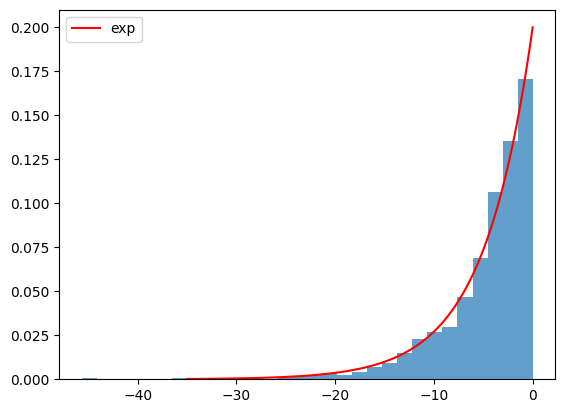

In [142]:
n = 500
X_n = np.max(np.random.uniform(0, theta, (1000, n)), axis=1)
data = n * (X_n-theta)
plt.hist(data, bins=30, density=True, alpha=0.7)
x = np.linspace(0, 35, 100)
plt.plot(-x, expon.pdf(x, scale=theta), 'r', label='exp')
plt.legend()
plt.show()


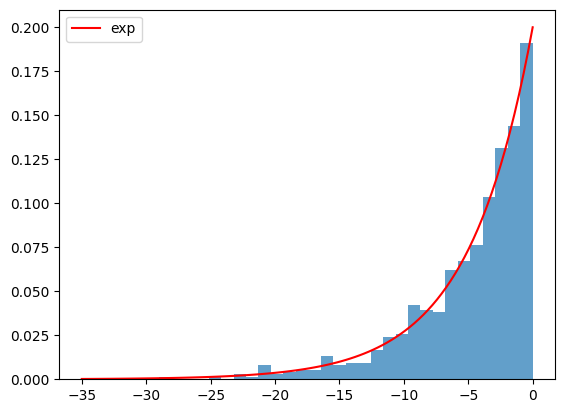

In [143]:
n = 20
X_n = np.max(np.random.uniform(0, theta, (1000, n)), axis=1)
data = n * (X_n-theta)
plt.hist(data, bins=30, density=True, alpha=0.7)
x = np.linspace(0, 35, 100)
plt.plot(-x, expon.pdf(x, scale=theta), 'r', label='exp')
plt.legend()
plt.show()
